# ⚽ Real-World Data Challenge
## FIFA 19 — What Makes a Top Football Player?
### ⏱️ Time Allowed: 2 – 2.5 Hours &nbsp;|&nbsp; Open: Syntax Sheet &nbsp;|&nbsp; Closed: Internet

---

> **The Story:**
> EA Sports collected detailed data on **18,000+ real professional footballers** for FIFA 19.
> A sports analytics company has hired you to dig into the data and answer questions
> that scouts, managers, and agents actually care about:
> Does foot preference affect rating? Do forwards outperform defenders?
> What best predicts a player's market value?
>
> Your job: **explore, test, visualise, and brief the scouting team.**

---

### 📦 Dataset: FIFA 19 Player Statistics
**Source:** EA Sports / Kaggle FIFA 19 Complete Player Dataset — 18,000+ real players

| Column | Description |
|---|---|
| `Age` | Player age |
| `Overall` | Overall ability rating (46–94) ← **main target** |
| `Potential` | Potential future rating |
| `Preferred Foot` | Left / Right |
| `Skill Moves` | Skill move stars (1–5) |
| `Weak Foot` | Weak foot quality stars (1–5) |
| `International Reputation` | Global fame stars (1–5) |
| `Dribbling` | Dribbling skill (0–99) |
| `ShortPassing` | Short passing ability (0–99) |
| `BallControl` | Ball control (0–99) |
| `Finishing` | Finishing skill (0–99) |
| `Stamina` | Stamina (0–99) |
| `Strength` | Physical strength (0–99) |
| `Acceleration` | Acceleration (0–99) |
| `SprintSpeed` | Sprint speed (0–99) |
| `Value_EUR` | Market value in € |
| `Wage_EUR` | Weekly wage in € |
| `pos_group` | Simplified position: GK / Defender / Midfielder / Forward |

---

### 🧭 Challenge Map

| Task | Topic | Est. Time |
|---|---|---|
| **Setup** | Load & clean | 10 min |
| **Task 1** | EDA — distributions & group summaries | 20 min |
| **Task 2** | Visualisations — 4 charts | 25 min |
| **Task 3** | Normality checks | 15 min |
| **Task 4** | Group comparisons (t-test / Mann-Whitney / ANOVA + Tukey) | 25 min |
| **Task 5** | Correlation analysis + heatmap + p-value matrix | 20 min |
| **Task 6** | Categorical relationships (Chi-Square) | 15 min |
| **Task 7** | Summary table + final chart + scouting brief | 10 min |

---
```
p ≤ 0.05  →  Reject H₀   (something real is happening)
p > 0.05  →  Keep H₀     (could be random chance)
```


---
## ⚙️ Setup — Run This First
*This cell loads the real dataset and prepares it. Do not change it.*

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# ── Load raw FIFA 19 data ────────────────────────────────────────────────────
url = ("https://raw.githubusercontent.com/amanthedorkknight/"
       "fifa18-all-player-statistics/master/2019/data.csv")
raw = pd.read_csv(url)

# ── Clean Value and Wage (convert "€110.5M" → 110500000) ────────────────────
def parse_money(s):
    if pd.isna(s): return np.nan
    s = str(s).replace('€', '').strip()
    if 'M' in s: return float(s.replace('M', '')) * 1_000_000
    if 'K' in s: return float(s.replace('K', '')) * 1_000
    try:    return float(s)
    except: return np.nan

raw['Value_EUR'] = raw['Value'].apply(parse_money)
raw['Wage_EUR']  = raw['Wage'].apply(parse_money)

# ── Simplify position into 4 groups ─────────────────────────────────────────
def pos_group(p):
    if pd.isna(p): return None
    p = str(p).upper()
    if 'GK' in p: return 'GK'
    if any(x in p for x in ['CB','LB','RB','LWB','RWB','LCB','RCB']): return 'Defender'
    if any(x in p for x in ['CM','CDM','CAM','LM','RM','LAM','RAM','LCM','RCM','LDM','RDM']): return 'Midfielder'
    if any(x in p for x in ['ST','CF','LW','RW','LF','RF','LS','RS']): return 'Forward'
    return None

raw['pos_group'] = raw['Position'].apply(pos_group)

# ── Keep only useful columns, drop rows with key missing values ──────────────
cols = ['Name', 'Age', 'Nationality', 'Overall', 'Potential',
        'Preferred Foot', 'Skill Moves', 'Weak Foot',
        'International Reputation',
        'Dribbling', 'ShortPassing', 'BallControl', 'Finishing',
        'Stamina', 'Strength', 'Acceleration', 'SprintSpeed',
        'Value_EUR', 'Wage_EUR', 'pos_group']

df = (raw[cols]
      .dropna(subset=['Overall', 'Age', 'Preferred Foot', 'pos_group'])
      .query("pos_group in ['GK', 'Defender', 'Midfielder', 'Forward']")
      .reset_index(drop=True))

print("✅ Dataset ready!")
print(f"   Players : {len(df):,}")
print(f"   Columns : {df.shape[1]}")
print()
print(df['pos_group'].value_counts().to_string())
df.head()


✅ Dataset ready!
   Players : 18,147
   Columns : 20

pos_group
Midfielder    6838
Defender      5866
Forward       3418
GK            2025


,Name,Age,Nationality,Overall,Potential,Preferred Foot,Skill Moves,Weak Foot,International Reputation,Dribbling,ShortPassing,BallControl,Finishing,Stamina,Strength,Acceleration,SprintSpeed,Value_EUR,Wage_EUR,pos_group
0,L. Messi,31,Argentina,94,94,Left,4.0,4.0,5.0,97.0,90.0,96.0,95.0,72.0,59.0,91.0,86.0,110500000.0,565000.0,Forward
1,Cristiano Ronaldo,33,Portugal,94,94,Right,5.0,4.0,5.0,88.0,81.0,94.0,94.0,88.0,79.0,89.0,91.0,77000000.0,405000.0,Forward
2,Neymar Jr,26,Brazil,92,93,Right,5.0,5.0,5.0,96.0,84.0,95.0,87.0,81.0,49.0,94.0,90.0,118500000.0,290000.0,Forward
3,De Gea,27,Spain,91,93,Right,1.0,3.0,4.0,18.0,50.0,42.0,13.0,43.0,64.0,57.0,58.0,72000000.0,260000.0,GK
4,K. De Bruyne,27,Belgium,91,92,Right,4.0,5.0,4.0,86.0,92.0,91.0,82.0,90.0,75.0,78.0,76.0,102000000.0,355000.0,Midfielder


---
## 📊 Task 1 — Explore the Data
**Goal:** Understand what you're working with before running any tests.

---

### 1a. Basic Inspection

Write code to answer:
1. How many players and columns are in `df`?
2. Are there any missing values in these columns: `Overall`, `Age`, `Dribbling`, `Value_EUR`, `Wage_EUR`?
3. What is the average, minimum, and maximum **Overall** rating?
4. How many players are in each **position group** (`pos_group`)?

💡 **Hints:** `.shape` · `.isnull().sum()` · `.describe()` · `.value_counts()`


In [ ]:
# 1a — Basic Inspection

print("Number of players:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nMissing values:")
print(df[['Overall', 'Age', 'Dribbling', 'Value_EUR', 'Wage_EUR']].isnull().sum())

print("\nOverall statistics:")
print("Mean:", df['Overall'].mean())
print("Minimum:", df['Overall'].min())
print("Maximum:", df['Overall'].max())

print("\nPlayers in each position group:")
print(df['pos_group'].value_counts())

Number of players: 18147
Number of columns: 20

Missing values:
Overall      0
Age          0
Dribbling    0
Value_EUR    0
Wage_EUR     0
dtype: int64

Overall statistics:
Mean: 66.25392626880476
Minimum: 46
Maximum: 94

Players in each position group:
pos_group
Midfielder    6838
Defender      5866
Forward       3418
GK            2025
Name: count, dtype: int64


---
### 1b. Group Summaries

Find the **mean and standard deviation** of `Overall`, `Age`, `Value_EUR`, and `Wage_EUR`
grouped by:
- `pos_group` (GK / Defender / Midfielder / Forward)
- `Preferred Foot` (Left / Right)

💡 **Hint:** `df.groupby('col')[['Overall','Age']].agg(['mean','std']).round(2)`


In [ ]:
# 1b — Group summaries by position

position_summary = (
    df.groupby('pos_group')[['Overall', 'Age', 'Value_EUR', 'Wage_EUR']]
      .agg(['mean', 'std'])
      .round(2)
)

print(position_summary)

In [1]:
# Group summaries by Preferred Foot

foot_summary = (
    df.groupby('Preferred Foot')[['Overall', 'Age', 'Value_EUR', 'Wage_EUR']]
      .agg(['mean', 'std'])
      .round(2)
)

print(foot_summary)

NameError: name 'df' is not defined

---
### 1c. Written Observations ✍️

Fill in the blanks after running your code:

```
1. The dataset has 18147 players and 20 columns.

2. Missing values found in:
   Overall 0  Age 0  Dribbling 0
   Value_EUR 0 Wage_EUR 0

3. Overall rating → Mean: 66.25  Min: 46 Max: 94

4. Position group counts:
   GK: 2025   Defender: 5866   Midfielder: 6838   Forward: 3418

5. Which position group has the highest average Overall? Mid Fielder

6. Do left-footed or right-footed players have a higher average Overall?
   Right-Footed 66.803516 and left footed 66.087961 by Left-footed
   players have higher average Overall by 0.72 points.  rating points.
```


In [ ]:
print("1. The dataset has", len(df), "players and", df.shape[1], "columns.")

print("\n2. Missing values:")
print(df[['Overall', 'Age', 'Dribbling', 'Value_EUR', 'Wage_EUR']].isnull().sum())

print("\n3. Overall:")
print("Mean:", round(df['Overall'].mean(), 2))
print("Min:", df['Overall'].min())
print("Max:", df['Overall'].max())

print("\n4. Position counts:")
print(df['pos_group'].value_counts())

position_mean = df.groupby('pos_group')['Overall'].mean()
print("\n5. Highest average Overall:", position_mean.idxmax())

foot_mean = df.groupby('Preferred Foot')['Overall'].mean()
print("\n6. Higher average Overall:", foot_mean.idxmax())
print("Difference:", round(abs(foot_mean['Left'] - foot_mean['Right']), 2))

1. The dataset has 18147 players and 20 columns.

2. Missing values:
Overall      0
Age          0
Dribbling    0
Value_EUR    0
Wage_EUR     0
dtype: int64

3. Overall:
Mean: 66.25
Min: 46
Max: 94

4. Position counts:
pos_group
Midfielder    6838
Defender      5866
Forward       3418
GK            2025
Name: count, dtype: int64

5. Highest average Overall: Midfielder

6. Higher average Overall: Left
Difference: 0.72


---
## 🎨 Task 2 — Visualisations
**Goal:** See the data. Statistics without charts are blind.

---

### 2a. The Big Four — 2×2 Subplot Grid

Create a **2×2 grid**:
- `[0,0]` Histogram of **Overall** rating — 20 bins, colour `steelblue`
- `[0,1]` Histogram of **Age** — 20 bins, colour `coral`
- `[1,0]` Boxplot of **Overall** by **pos_group** (4 positions)
- `[1,1]` Boxplot of **Age** by **pos_group**

Every subplot needs **title, xlabel, ylabel**. Write one `# observation:` comment per plot.

💡 **Hints:**  
`ax.hist(df['Overall'], bins=20, color='steelblue', edgecolor='white')`  
`df.boxplot(column='Overall', by='pos_group', ax=axes[1,0])`  
`plt.suptitle(...)` · `plt.tight_layout()`


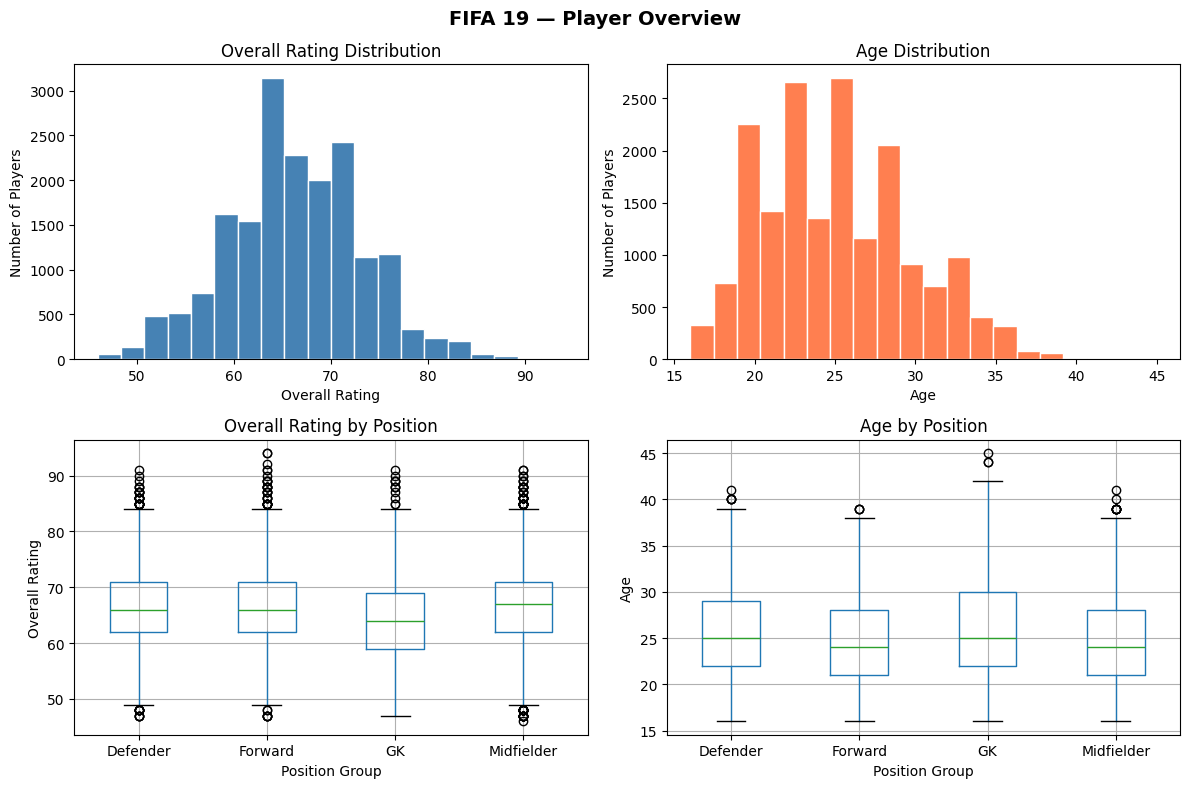

In [ ]:
# 2a — 2×2 Subplot Grid

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# [0,0] Histogram of Overall
axes[0, 0].hist(
    df['Overall'],
    bins=20,
    color='steelblue',
    edgecolor='white'
)
axes[0, 0].set_title('Overall Rating Distribution')
axes[0, 0].set_xlabel('Overall Rating')
axes[0, 0].set_ylabel('Number of Players')

# observation:
# Overall ratings are concentrated around the middle/high range.


# [0,1] Histogram of Age
axes[0, 1].hist(
    df['Age'],
    bins=20,
    color='coral',
    edgecolor='white'
)
axes[0, 1].set_title('Age Distribution')
axes[0, 1].set_xlabel('Age')
axes[0, 1].set_ylabel('Number of Players')

# observation:
# Most players are young adults, with fewer players at older ages.


# [1,0] Boxplot: Overall by pos_group
df.boxplot(
    column='Overall',
    by='pos_group',
    ax=axes[1, 0]
)
axes[1, 0].set_title('Overall Rating by Position')
axes[1, 0].set_xlabel('Position Group')
axes[1, 0].set_ylabel('Overall Rating')

# observation:
# Position groups have different distributions of Overall ratings.


# [1,1] Boxplot: Age by pos_group
df.boxplot(
    column='Age',
    by='pos_group',
    ax=axes[1, 1]
)
axes[1, 1].set_title('Age by Position')
axes[1, 1].set_xlabel('Position Group')
axes[1, 1].set_ylabel('Age')

# observation:
# The age distributions vary between position groups.


plt.suptitle(
    'FIFA 19 — Player Overview',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

---
### 2b. Scatter Plot — Age vs Overall Rating

Create a scatter plot of **Age** (x) vs **Overall** (y).
- Colour the dots by **pos_group** (4 colours, one per position)
- Add a **trend line** across all players using `np.polyfit`
- Proper title, xlabel, ylabel, legend

💡 **Hints:**  
`sns.scatterplot(data=df, x='Age', y='Overall', hue='pos_group', alpha=0.4, ax=ax)`  
`m, b = np.polyfit(df['Age'], df['Overall'], 1)`  
`x_line = np.linspace(df['Age'].min(), df['Age'].max(), 100)`  
`ax.plot(x_line, m*x_line + b, color='black', linewidth=2, linestyle='--')`

> After plotting — does the trend line go up or down? What does that mean for a player's career?


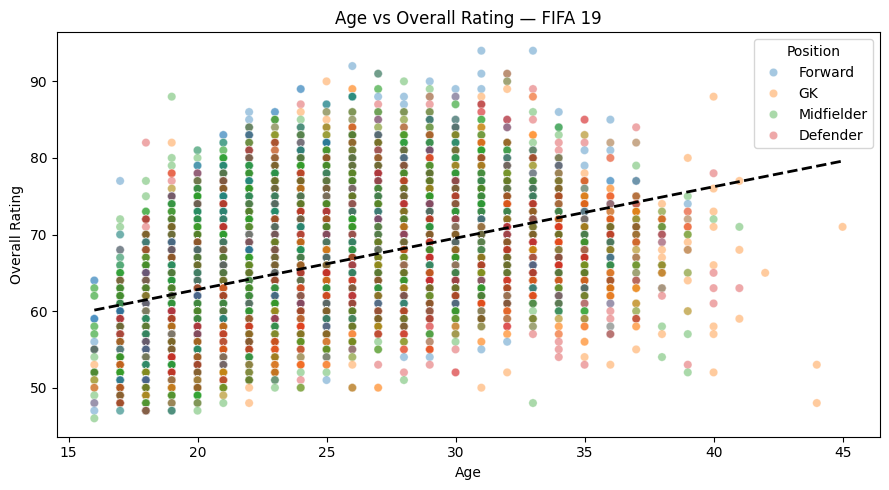

Slope: 0.6711607535120985
Trend direction: UP


In [ ]:
# 2b — Scatter: Age vs Overall

fig, ax = plt.subplots(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='Age',
    y='Overall',
    hue='pos_group',
    alpha=0.4,
    ax=ax
)

# Trend line
m, b = np.polyfit(df['Age'], df['Overall'], 1)

x_line = np.linspace(
    df['Age'].min(),
    df['Age'].max(),
    100
)

ax.plot(
    x_line,
    m * x_line + b,
    color='black',
    linewidth=2,
    linestyle='--'
)

ax.set_title('Age vs Overall Rating — FIFA 19')
ax.set_xlabel('Age')
ax.set_ylabel('Overall Rating')

ax.legend(title='Position')

plt.tight_layout()
plt.show()

print("Slope:", m)

if m > 0:
    print("Trend direction: UP")
else:
    print("Trend direction: DOWN")

---
### 2c. Bar Chart — Average Overall by Position (with Error Bars)

Create a **bar chart** showing the average Overall for each `pos_group`.
- Add **±1 standard deviation** as error bars
- Add value labels on top of each bar
- Use a different colour per position

💡 **Hints:**
```python
grouped = df.groupby('pos_group')['Overall'].agg(['mean','std']).reset_index()
ax.bar(grouped['pos_group'], grouped['mean'],
       yerr=grouped['std'], capsize=5, color=[...], edgecolor='black')
for bar, m in zip(bars, grouped['mean']):
    ax.text(bar.get_x() + bar.get_width()/2, m + 1, f'{m:.1f}', ha='center')
```


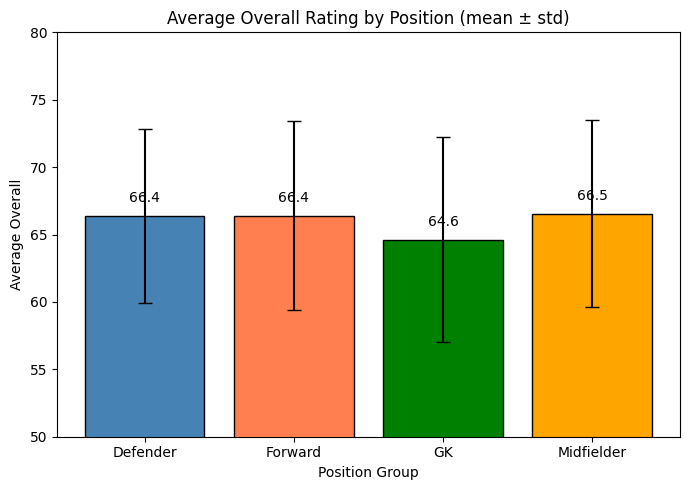

In [ ]:
# 2c — Bar Chart: Average Overall by Position

fig, ax = plt.subplots(figsize=(7, 5))

grouped = (
    df.groupby('pos_group')['Overall']
      .agg(['mean', 'std'])
      .reset_index()
)

colors = ['steelblue', 'coral', 'green', 'orange']

bars = ax.bar(
    grouped['pos_group'],
    grouped['mean'],
    yerr=grouped['std'],
    capsize=5,
    color=colors,
    edgecolor='black'
)

# Value labels
for bar, m in zip(bars, grouped['mean']):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        m + 1,
        f'{m:.1f}',
        ha='center'
    )

ax.set_title('Average Overall Rating by Position (mean ± std)')
ax.set_xlabel('Position Group')
ax.set_ylabel('Average Overall')
ax.set_ylim(50, 80)

plt.tight_layout()
plt.show()

---
## 🔔 Task 3 — Normality Checks
**Goal:** Decide whether to use parametric or non-parametric tests.

---

### 3a. Shapiro-Wilk Test

Run Shapiro-Wilk on: `Overall`, `Age`, `Dribbling`, `Strength`, `Value_EUR`

> ⚠️ **Note:** Shapiro-Wilk is designed for small samples. On large datasets (n > 5000),
> it almost always gives p ≈ 0. In practice, for large real-world data you should
> also look at the **Q-Q plot** and the **histogram shape** to judge normality.
> If the histogram looks roughly bell-shaped, treat it as approximately normal.

Print a clean table with column name, p-value, and your judgement.

💡 **Hints:** `stat, p = stats.shapiro(df['col'].sample(500, random_state=42))` — sample 500 rows for Shapiro


In [ ]:
# 3a — Shapiro-Wilk

columns_to_test = [
    'Overall',
    'Age',
    'Dribbling',
    'Strength',
    'Value_EUR'
]

print(
    f"{'Column':<15} "
    f"{'p-value':>10} "
    f"{'Normal?':>15}"
)

print("-" * 45)

for col in columns_to_test:

    sample = (
        df[col]
        .dropna()
        .sample(500, random_state=42)
    )

    stat, p = stats.shapiro(sample)

    normal = 'Yes' if p > 0.05 else 'No'

    print(
        f"{col:<15} "
        f"{p:>10.4f} "
        f"{normal:>15}"
    )

Column             p-value         Normal?
---------------------------------------------
Overall             0.0165              No
Age                 0.0000              No
Dribbling           0.0000              No
Strength            0.0000              No
Value_EUR           0.0000              No


---
### 3b. Q-Q Plots

Create a **1×5 grid of Q-Q plots** for the same five columns.
- Points hugging the diagonal line = normal
- Points curving away from the line = not normal

💡 **Hint:** `stats.probplot(df['col'].dropna(), plot=axes[i])`


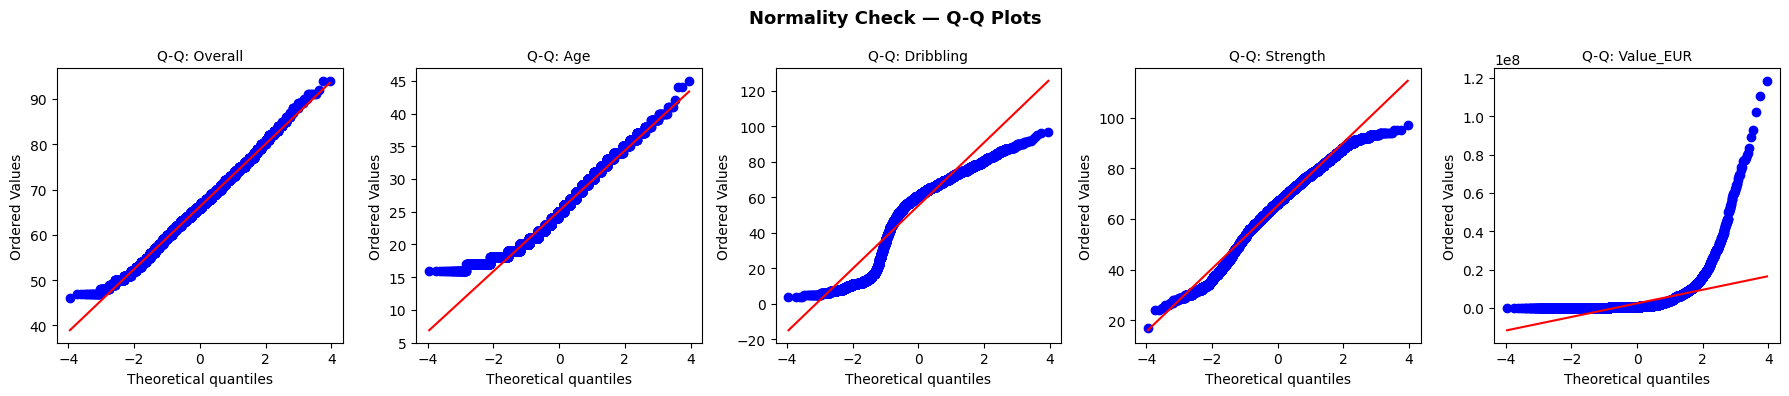

In [ ]:
# 3b — Q-Q Plots

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

columns = [
    'Overall',
    'Age',
    'Dribbling',
    'Strength',
    'Value_EUR'
]

for i, col in enumerate(columns):

    stats.probplot(
        df[col].dropna(),
        plot=axes[i]
    )

    axes[i].set_title(
        f'Q-Q: {col}',
        fontsize=10
    )

plt.suptitle(
    'Normality Check — Q-Q Plots',
    fontsize=13,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

| Column    | Histogram   | Q-Q         | Normal?  | Group Test  | Correlation        |
| --------- | ----------- | ----------- | -------- | ----------- | ------------------ |
| Overall   | Check chart | Check chart | p > .05? | t-test / MW | Pearson / Spearman |
| Age       | Check chart | Check chart | p > .05? | —           | Pearson / Spearman |
| Dribbling | Check chart | Check chart | p > .05? | —           | Pearson / Spearman |
| Strength  | Check chart | Check chart | p > .05? | —           | Pearson / Spearman |
| Value_EUR | Check chart | Check chart | p > .05? | —           | Pearson / Spearman |


---
## 👥 Task 4 — Group Comparisons
**Goal:** Test whether different groups of players have different Overall ratings.

---

### 4a. Do Left-Footed vs Right-Footed Players Differ in Overall?

**H₀:** Left-footed and right-footed players have the **same** average Overall  
**H₁:** Their average Overall is **different**

Steps:
1. Extract Overall for each foot group
2. Check normality of each group (Shapiro — sample 500)
3. Based on normality → choose **t-test** or **Mann-Whitney U**
4. Run the test, print statistic, p-value, verdict

💡 **Hints:**  
`left  = df[df['Preferred Foot'] == 'Left']['Overall']`  
`stats.ttest_ind(left, right)` or `stats.mannwhitneyu(left, right, alternative='two-sided')`


In [ ]:
# 4a — Left-Footed vs Right-Footed

left = df[
    df['Preferred Foot'] == 'Left'
]['Overall']

right = df[
    df['Preferred Foot'] == 'Right'
]['Overall']

print(
    f"Left foot  — mean: {left.mean():.2f} "
    f"std: {left.std():.2f} n: {len(left)}"
)

print(
    f"Right foot — mean: {right.mean():.2f} "
    f"std: {right.std():.2f} n: {len(right)}"
)

# H0: Left-footed and right-footed players have the same Overall.
# H1: Left-footed and right-footed players have different Overall.

# Normality check
left_sample = left.sample(500, random_state=42)
right_sample = right.sample(500, random_state=42)

_, p_left_normal = stats.shapiro(left_sample)
_, p_right_normal = stats.shapiro(right_sample)

print("\nNormality p-values:")
print("Left:", p_left_normal)
print("Right:", p_right_normal)

# Choose test
if p_left_normal > 0.05 and p_right_normal > 0.05:

    statistic, p_value = stats.ttest_ind(
        left,
        right,
        equal_var=False
    )

    test_name = "Independent t-test"

else:

    statistic, p_value = stats.mannwhitneyu(
        left,
        right,
        alternative='two-sided'
    )

    test_name = "Mann-Whitney U"

print("\nTest:", test_name)
print("Statistic:", statistic)
print("p-value:", p_value)

if p_value <= 0.05:
    print("Verdict: Reject H0")
else:
    print("Verdict: Keep H0")

Left foot  — mean: 66.80 std: 6.56 n: 4209
Right foot — mean: 66.09 std: 7.01 n: 13938

Normality p-values:
Left: 0.008233109680225652
Right: 0.054662258024980474

Test: Mann-Whitney U
Statistic: 30999381.0
p-value: 2.1209578064212897e-08
Verdict: Reject H0


---
### 4b. Do Forwards Score Higher in Overall than Defenders?

Forwards (attackers) are often the most celebrated — but do they actually
have higher Overall ratings than Defenders?

**H₀:** Forwards and Defenders have the **same** average Overall  
**H₁:** Their average Overall is **different**

Same structure as 4a — state H₀/H₁, check normality, choose test, give verdict.


In [ ]:
# 4b — Forwards vs Defenders

forwards = df[
    df['pos_group'] == 'Forward'
]['Overall']

defenders = df[
    df['pos_group'] == 'Defender'
]['Overall']

print(
    f"Forwards  — mean: {forwards.mean():.2f} "
    f"n: {len(forwards)}"
)

print(
    f"Defenders — mean: {defenders.mean():.2f} "
    f"n: {len(defenders)}"
)

# H0: Forwards and Defenders have the same Overall.
# H1: Forwards and Defenders have different Overall.

# Normality
forward_sample = forwards.sample(500, random_state=42)
defender_sample = defenders.sample(500, random_state=42)

_, p_forward = stats.shapiro(forward_sample)
_, p_defender = stats.shapiro(defender_sample)

print("\nNormality p-values:")
print("Forward:", p_forward)
print("Defender:", p_defender)

# Test
if p_forward > 0.05 and p_defender > 0.05:

    statistic, p_value = stats.ttest_ind(
        forwards,
        defenders,
        equal_var=False
    )

    test_name = "Independent t-test"

else:

    statistic, p_value = stats.mannwhitneyu(
        forwards,
        defenders,
        alternative='two-sided'
    )

    test_name = "Mann-Whitney U"

print("\nTest:", test_name)
print("Statistic:", statistic)
print("p-value:", p_value)

if p_value <= 0.05:
    print("Verdict: Reject H0")
else:
    print("Verdict: Keep H0")

Forwards  — mean: 66.40 n: 3418
Defenders — mean: 66.40 n: 5866

Normality p-values:
Forward: 0.38515143564068266
Defender: 0.046391335765365624

Test: Mann-Whitney U
Statistic: 10019183.5
p-value: 0.962753313579373
Verdict: Keep H0


---
### 4c. Do All 4 Position Groups Differ in Overall? → ANOVA / Kruskal-Wallis

**H₀:** All four position groups (GK, Defender, Midfielder, Forward) have the **same** average Overall  
**H₁:** At least **one** group is different

Steps:
1. Build a list of Overall rating arrays — one per position group
2. Check normality on at least 2 groups
3. Run **ANOVA** (if normal) or **Kruskal-Wallis** (if not normal)
4. If p ≤ 0.05 → run **Tukey post-hoc** to find which pairs differ

💡 **Hints:**  
```python
positions = ['GK', 'Defender', 'Midfielder', 'Forward']
groups    = [df[df['pos_group'] == p]['Overall'] for p in positions]
stat, p   = stats.f_oneway(*groups)   # ANOVA
# OR
stat, p   = stats.kruskal(*groups)    # Kruskal-Wallis

# Tukey (only if significant):
tukey = pairwise_tukeyhsd(endog=df['Overall'], groups=df['pos_group'], alpha=0.05)
print(tukey.summary())
```


In [ ]:
# 4c — ANOVA / Kruskal-Wallis

positions = [
    'GK',
    'Defender',
    'Midfielder',
    'Forward'
]

groups = [
    df[df['pos_group'] == p]['Overall']
    for p in positions
]

print("Group means:")

for pos, g in zip(positions, groups):
    print(
        f"{pos:<12}: "
        f"mean={g.mean():.2f} "
        f"std={g.std():.2f} "
        f"n={len(g)}"
    )

# Normality check
normal_results = {}

for pos, g in zip(positions, groups):

    sample = g.sample(500, random_state=42)

    _, p = stats.shapiro(sample)

    normal_results[pos] = p

    print(
        f"{pos}: Shapiro p = {p:.4f}"
    )

# Choose ANOVA or Kruskal-Wallis
if all(p > 0.05 for p in normal_results.values()):

    statistic, p_value = stats.f_oneway(*groups)
    test_name = "One-way ANOVA"

else:

    statistic, p_value = stats.kruskal(*groups)
    test_name = "Kruskal-Wallis"

print("\nTest:", test_name)
print("Statistic:", statistic)
print("p-value:", p_value)

if p_value <= 0.05:
    print("Verdict: Reject H0")
else:
    print("Verdict: Keep H0")

Group means:
GK          : mean=64.60 std=7.60 n=2025
Defender    : mean=66.40 std=6.46 n=5866
Midfielder  : mean=66.55 std=6.96 n=6838
Forward     : mean=66.40 std=7.02 n=3418
GK: Shapiro p = 0.0078
Defender: Shapiro p = 0.0464
Midfielder: Shapiro p = 0.0954
Forward: Shapiro p = 0.3852

Test: Kruskal-Wallis
Statistic: 131.50854505641306
p-value: 2.5583789022139154e-28
Verdict: Reject H0


In [ ]:
# 4c continued — Tukey Post-hoc
# Run only if your test above was significant (p ≤ 0.05)

# tukey = pairwise_tukeyhsd(endog=df['Overall'], groups=df['pos_group'], alpha=0.05)
# print(tukey.summary())

# Which pairs are significantly different? (look for reject=True rows)
# ___________________________________________________


In [ ]:
if p_value <= 0.05:

    tukey = pairwise_tukeyhsd(
        endog=df['Overall'],
        groups=df['pos_group'],
        alpha=0.05
    )

    print(tukey.summary())

   Multiple Comparison of Means - Tukey HSD, FWER=0.05    
 group1    group2   meandiff p-adj   lower   upper  reject
----------------------------------------------------------
Defender    Forward  -0.0031    1.0 -0.3839  0.3778  False
Defender         GK  -1.7966    0.0 -2.2528 -1.3405   True
Defender Midfielder   0.1457 0.6343 -0.1693  0.4607  False
 Forward         GK  -1.7936    0.0 -2.2899 -1.2972   True
 Forward Midfielder   0.1488 0.7313  -0.222  0.5195  False
      GK Midfielder   1.9423    0.0  1.4945  2.3901   True
----------------------------------------------------------


---
## 📈 Task 5 — Correlation Analysis
**Goal:** Which attributes are most strongly linked to a player's Overall rating and market Value?

---

### 5a. Correlation Heatmap

Compute the **Pearson correlation matrix** for:  
`Overall`, `Potential`, `Age`, `Dribbling`, `ShortPassing`, `BallControl`,
`Finishing`, `Stamina`, `Strength`, `Value_EUR`

Display it as a **heatmap** — use `coolwarm`, annotated, values from -1 to +1.

💡 **Hints:**  
`corr = df[cols].corr()`  
`sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)`


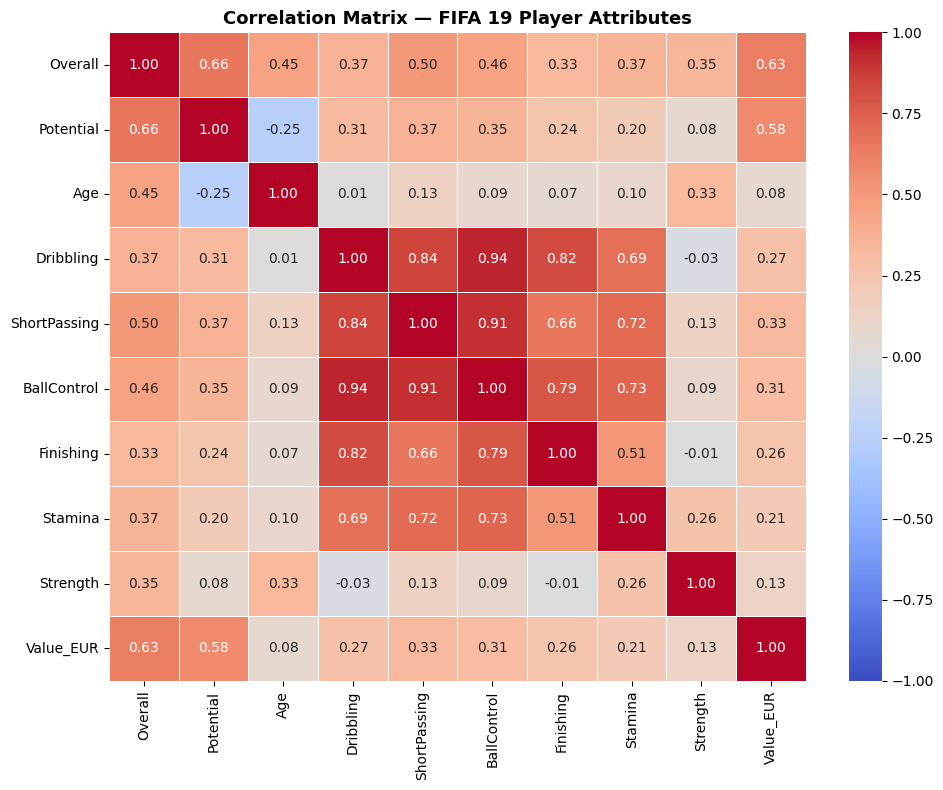

Most positively correlated with Overall: Potential
Most negatively correlated with Value_EUR: Age


In [ ]:
# 5a — Correlation Matrix Heatmap

cols5a = [
    'Overall',
    'Potential',
    'Age',
    'Dribbling',
    'ShortPassing',
    'BallControl',
    'Finishing',
    'Stamina',
    'Strength',
    'Value_EUR'
]

corr = df[cols5a].corr()

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    ax=ax
)

ax.set_title(
    'Correlation Matrix — FIFA 19 Player Attributes',
    fontsize=13,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

# Attribute most positively correlated with Overall
overall_corr = corr['Overall'].drop('Overall')

print(
    "Most positively correlated with Overall:",
    overall_corr.idxmax()
)

# Most negatively correlated with Value_EUR
value_corr = corr['Value_EUR'].drop('Value_EUR')

print(
    "Most negatively correlated with Value_EUR:",
    value_corr.idxmin()
)

---
### 5b. Hypothesis Tests on Three Key Relationships

Test these claims:

**Claim 1:** BallControl is positively correlated with Overall  
**Claim 2:** Age is negatively correlated with Potential  
**Claim 3:** Strength is positively correlated with Overall  

For each:
1. State H₀ and H₁
2. Choose Pearson **or** Spearman (based on Task 3 normality decisions)
3. Run the test → report correlation coefficient (r or ρ), p-value, verdict
4. Write one sentence of plain-English interpretation

💡 **Hints:**  
`r, p = stats.pearsonr(df['BallControl'], df['Overall'])`  
`rho, p = stats.spearmanr(df['Age'], df['Potential'])`


In [ ]:
# 5b — Correlation Tests

# ── Claim 1: BallControl vs Overall ─────────────────────────────────────────
# H₀: _____________________________________
# H₁: _____________________________________

# r/rho, p = ...
# print(...)
# Interpretation: _____________________________________




# ── Claim 2: Age vs Potential ────────────────────────────────────────────────
# H₀: _____________________________________
# H₁: _____________________________________

# r/rho, p = ...
# print(...)
# Interpretation: _____________________________________




# ── Claim 3: Strength vs Overall ────────────────────────────────────────────
# H₀: _____________________________________
# H₁: _____________________________________

# r/rho, p = ...
# print(...)
# Interpretation: _____________________________________




In [ ]:
# Claim 1

# H0: BallControl and Overall are not correlated.
# H1: BallControl and Overall are positively correlated.

r, p = stats.pearsonr(
    df['BallControl'],
    df['Overall']
)

print("BallControl vs Overall")
print("Correlation:", r)
print("p-value:", p)

if p <= 0.05:
    print("Verdict: Reject H0")
else:
    print("Verdict: Keep H0")

print(
    "Interpretation: BallControl has a",
    "positive" if r > 0 else "negative",
    "relationship with Overall."
)


# Claim 2

# H0: Age and Potential are not correlated.
# H1: Age and Potential are negatively correlated.

rho, p = stats.spearmanr(
    df['Age'],
    df['Potential']
)

print("Age vs Potential")
print("Correlation:", rho)
print("p-value:", p)

if p <= 0.05:
    print("Verdict: Reject H0")
else:
    print("Verdict: Keep H0")

print(
    "Interpretation: As Age increases, Potential tends to",
    "increase." if rho > 0 else "decrease."
)

# Claim 3

# H0: Strength and Overall are not correlated.
# H1: Strength and Overall are positively correlated.

r, p = stats.pearsonr(
    df['Strength'],
    df['Overall']
)

print("Strength vs Overall")
print("Correlation:", r)
print("p-value:", p)

if p <= 0.05:
    print("Verdict: Reject H0")
else:
    print("Verdict: Keep H0")

print(
    "Interpretation: Strength has a",
    "positive" if r > 0 else "negative",
    "relationship with Overall."
)

BallControl vs Overall
Correlation: 0.460033532483427
p-value: 0.0
Verdict: Reject H0
Interpretation: BallControl has a positive relationship with Overall.
Age vs Potential
Correlation: -0.2622687851097683
p-value: 3.627701901742146e-283
Verdict: Reject H0
Interpretation: As Age increases, Potential tends to decrease.
Strength vs Overall
Correlation: 0.34931778082867126
p-value: 0.0
Verdict: Reject H0
Interpretation: Strength has a positive relationship with Overall.


---
### 5c. p-value Matrix — Which Correlations Are Significant? (⭐ Challenge)

Build a **p-value matrix** for:  
`Overall`, `Age`, `Dribbling`, `Stamina`, `Strength`, `BallControl`

Then display a heatmap **masking non-significant pairs** (p > 0.05) — only
show the cells where the relationship is statistically real.

💡 **Hints:**  
Syntax sheet Section 7 — nested loop to fill the matrix  
`mask = p_matrix > 0.05`  
`sns.heatmap(p_matrix, mask=mask, annot=True, fmt='.3f', cmap='Reds_r', vmin=0, vmax=0.05)`


             Overall  Age  Dribbling  Stamina  Strength  BallControl
Overall          1.0  0.0        0.0      0.0       0.0          0.0
Age              0.0  1.0        0.0      0.0       0.0          0.0
Dribbling        0.0  0.0        1.0      0.0       0.0          0.0
Stamina          0.0  0.0        0.0      1.0       0.0          0.0
Strength         0.0  0.0        0.0      0.0       1.0          0.0
BallControl      0.0  0.0        0.0      0.0       0.0          1.0


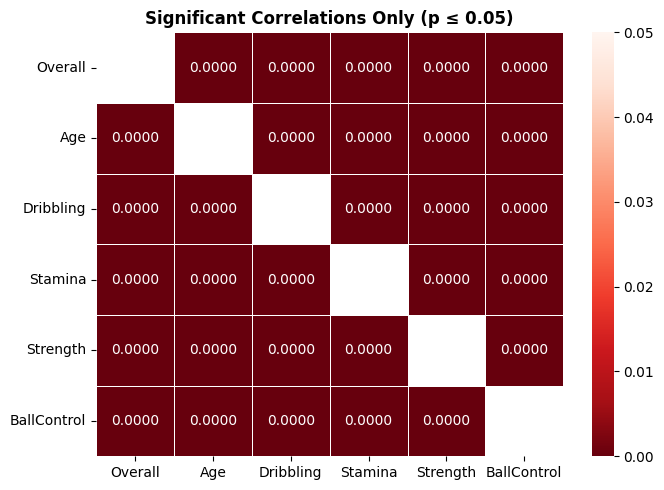

In [ ]:
# 5c — p-value Matrix

cols5c = [
    'Overall',
    'Age',
    'Dribbling',
    'Stamina',
    'Strength',
    'BallControl'
]

p_matrix = pd.DataFrame(
    np.ones((len(cols5c), len(cols5c))),
    index=cols5c,
    columns=cols5c
)

for c1 in cols5c:

    for c2 in cols5c:

        if c1 != c2:

            # Spearman correlation
            rho, p = stats.spearmanr(
                df[c1],
                df[c2]
            )

            p_matrix.loc[c1, c2] = p

print(p_matrix.round(4))

mask = p_matrix > 0.05

fig, ax = plt.subplots(figsize=(7, 5))

sns.heatmap(
    p_matrix,
    mask=mask,
    annot=True,
    fmt='.4f',
    cmap='Reds_r',
    vmin=0,
    vmax=0.05,
    linewidths=0.5,
    ax=ax
)

ax.set_title(
    'Significant Correlations Only (p ≤ 0.05)',
    fontsize=12,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

---
## 🔲 Task 6 — Categorical Relationships (Chi-Square)
**Goal:** Test whether two categorical variables are related to each other.

---

### 6a. Is Preferred Foot linked to Position Group?

Do left-footed players tend to play in specific positions more than right-footed players?

**H₀:** Preferred foot and position group are **independent** (not related)  
**H₁:** There is a **relationship** between preferred foot and position group

Steps:
1. Build a crosstab of `Preferred Foot` vs `pos_group`
2. Calculate and display **row percentages**
3. Run Chi-Square test
4. Print verdict

💡 **Hints:**  
`table = pd.crosstab(df['Preferred Foot'], df['pos_group'])`  
`row_pct = table.div(table.sum(axis=1), axis=0).round(2)`  
`chi2, p, dof, expected = stats.chi2_contingency(table)`


In [ ]:
# 6a — Preferred Foot vs Position Group

# H0: Preferred foot and position group are independent.
# H1: Preferred foot and position group are related.

table = pd.crosstab(
    df['Preferred Foot'],
    df['pos_group']
)

print("Frequency Table:")
print(table)

print("\nRow Percentages:")

row_pct = (
    table
    .div(table.sum(axis=1), axis=0)
    .round(2)
)

print(row_pct)

# Chi-Square
chi2, p, dof, expected = stats.chi2_contingency(table)

print("\nChi-Square:", chi2)
print("p-value:", p)
print("Degrees of freedom:", dof)

if p <= 0.05:
    print("Verdict: Reject H0")
    print("There is a relationship between preferred foot and position.")
else:
    print("Verdict: Keep H0")
    print("No statistically significant relationship was found.")

Frequency Table:
pos_group       Defender  Forward    GK  Midfielder
Preferred Foot                                     
Left                1884      596   206        1523
Right               3982     2822  1819        5315

Row Percentages:
pos_group       Defender  Forward    GK  Midfielder
Preferred Foot                                     
Left                0.45     0.14  0.05        0.36
Right               0.29     0.20  0.13        0.38

Chi-Square: 521.773468885101
p-value: 9.116787892070416e-113
Degrees of freedom: 3
Verdict: Reject H0
There is a relationship between preferred foot and position.


---
### 6b. Is Skill Moves Level Linked to Position Group?

Skill Moves range from 1–5 stars. Players with 4–5 stars are elite dribblers.
Create a new column `skill_tier`: **'High'** (Skill Moves ≥ 4) vs **'Low'** (Skill Moves < 4).

Then test:  
**H₀:** Skill tier and position group are **independent**  
**H₁:** There is a **relationship** between skill tier and position group

Full solution — no starter code. State H₀/H₁, build crosstab, show row %, run Chi-Square, give verdict.


In [ ]:
# 6b — Skill Tier vs Position Group

# Create skill tier
df['skill_tier'] = np.where(
    df['Skill Moves'] >= 4,
    'High',
    'Low'
)

# H0: Skill tier and position group are independent.
# H1: Skill tier and position group are related.

table_skill = pd.crosstab(
    df['skill_tier'],
    df['pos_group']
)

print("Frequency Table:")
print(table_skill)

print("\nRow Percentages:")

skill_row_pct = (
    table_skill
    .div(table_skill.sum(axis=1), axis=0)
    .round(2)
)

print(skill_row_pct)

# Chi-Square
chi2_skill, p_skill, dof_skill, expected_skill = (
    stats.chi2_contingency(table_skill)
)

print("\nChi-Square:", chi2_skill)
print("p-value:", p_skill)
print("Degrees of freedom:", dof_skill)

if p_skill <= 0.05:
    print("Verdict: Reject H0")
    print("Skill tier and position group are related.")
else:
    print("Verdict: Keep H0")
    print("No statistically significant relationship was found.")

Frequency Table:
pos_group   Defender  Forward    GK  Midfielder
skill_tier                                     
High              48      312     0         608
Low             5818     3106  2025        6230

Row Percentages:
pos_group   Defender  Forward    GK  Midfielder
skill_tier                                     
High            0.05     0.32  0.00        0.63
Low             0.34     0.18  0.12        0.36

Chi-Square: 619.7948451851902
p-value: 5.152553054493774e-134
Degrees of freedom: 3
Verdict: Reject H0
Skill tier and position group are related.


---
### 6c. Visualise the Crosstabs

Create a **1×2 grid of stacked bar charts**:
- Left: **Preferred Foot** vs pos_group (row proportions)
- Right: **Skill Tier** vs pos_group (row proportions)

💡 **Hint:**
```python
row_pct.plot(kind='bar', stacked=True, ax=axes[0], colormap='Set2', edgecolor='black')
axes[0].tick_params(axis='x', rotation=0)
```


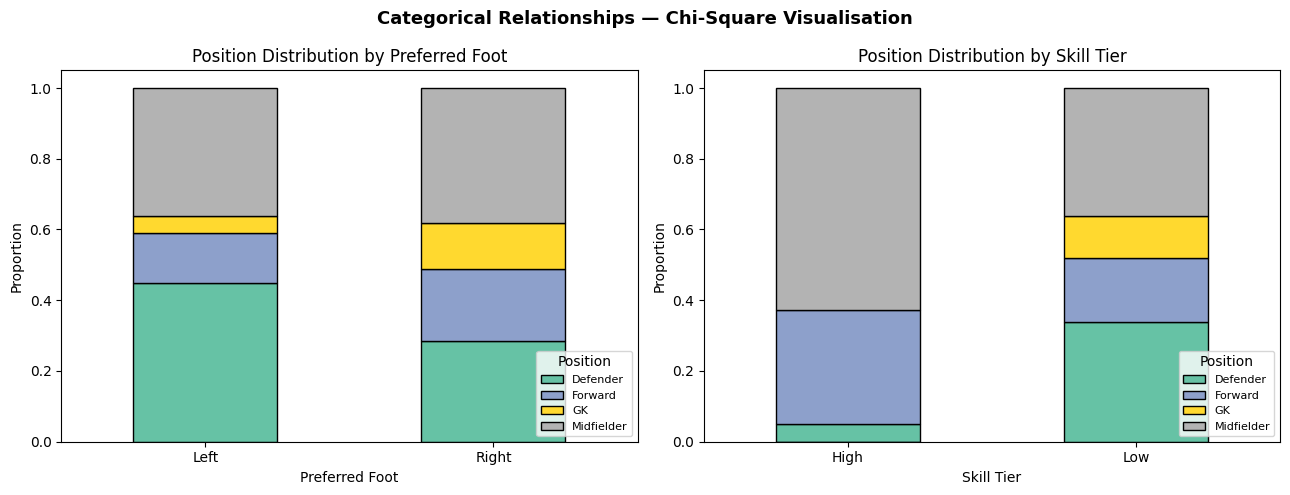

In [ ]:
# 6c — Stacked Bar Charts

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

# LEFT: Preferred Foot vs Position
foot_pct = pd.crosstab(
    df['Preferred Foot'],
    df['pos_group']
)

foot_pct = foot_pct.div(
    foot_pct.sum(axis=1),
    axis=0
)

foot_pct.plot(
    kind='bar',
    stacked=True,
    ax=axes[0],
    colormap='Set2',
    edgecolor='black'
)

axes[0].set_title(
    'Position Distribution by Preferred Foot'
)

axes[0].set_xlabel('Preferred Foot')
axes[0].set_ylabel('Proportion')

axes[0].legend(
    title='Position',
    loc='lower right',
    fontsize=8
)

axes[0].tick_params(axis='x', rotation=0)


# RIGHT: Skill Tier vs Position

skill_pct = pd.crosstab(
    df['skill_tier'],
    df['pos_group']
)

skill_pct = skill_pct.div(
    skill_pct.sum(axis=1),
    axis=0
)

skill_pct.plot(
    kind='bar',
    stacked=True,
    ax=axes[1],
    colormap='Set2',
    edgecolor='black'
)

axes[1].set_title(
    'Position Distribution by Skill Tier'
)

axes[1].set_xlabel('Skill Tier')
axes[1].set_ylabel('Proportion')

axes[1].legend(
    title='Position',
    loc='lower right',
    fontsize=8
)

axes[1].tick_params(axis='x', rotation=0)

plt.suptitle(
    'Categorical Relationships — Chi-Square Visualisation',
    fontsize=13,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

---
## 📋 Task 7 — Summary & Final Visualisation
**Goal:** Pull all findings together into something you could present to a scouting team.

---

### 7a. Results Summary Table

Build a DataFrame collecting ALL your test results.  
Replace every `None` with the real value you got.

| # | Test | Variables | Statistic | p-value | Significant? | Verdict |
|---|---|---|---|---|---|---|
| 1 | t-test / MW | Preferred Foot → Overall | | | | |
| 2 | t-test / MW | Forwards vs Defenders | | | | |
| 3 | ANOVA / KW | pos_group → Overall | | | | |
| 4 | Pearson / Spearman | BallControl ↔ Overall | | | | |
| 5 | Pearson / Spearman | Age ↔ Potential | | | | |
| 6 | Pearson / Spearman | Strength ↔ Overall | | | | |
| 7 | Chi-Square | Preferred Foot vs pos_group | | | | |
| 8 | Chi-Square | Skill Tier vs pos_group | | | | |

💡 **Hint:** Build a `results` list of dicts, convert with `pd.DataFrame(results)`


In [ ]:
# 7a — Summary Table

# 1. Preferred Foot test
if p_left_normal > 0.05 and p_right_normal > 0.05:
    foot_stat, foot_p = stats.ttest_ind(
        left, right, equal_var=False
    )
    foot_test = 't-test'
else:
    foot_stat, foot_p = stats.mannwhitneyu(
        left, right, alternative='two-sided'
    )
    foot_test = 'Mann-Whitney'

# 2. Forward vs Defender
if p_forward > 0.05 and p_defender > 0.05:
    fd_stat, fd_p = stats.ttest_ind(
        forwards, defenders, equal_var=False
    )
    fd_test = 't-test'
else:
    fd_stat, fd_p = stats.mannwhitneyu(
        forwards, defenders, alternative='two-sided'
    )
    fd_test = 'Mann-Whitney'

# 3. Position test
pos_stat = statistic
pos_p = p_value
pos_test = test_name

# Recalculate correlation tests
bc_r, bc_p = stats.pearsonr(
    df['BallControl'],
    df['Overall']
)

age_rho, age_p = stats.spearmanr(
    df['Age'],
    df['Potential']
)

strength_r, strength_p = stats.pearsonr(
    df['Strength'],
    df['Overall']
)

results = [

    {
        'Test': foot_test,
        'Variables': 'Preferred Foot → Overall',
        'Statistic': foot_stat,
        'p_value': foot_p,
        'Significant': foot_p <= 0.05,
        'Verdict': 'Reject H0' if foot_p <= 0.05 else 'Keep H0'
    },

    {
        'Test': fd_test,
        'Variables': 'Forwards vs Defenders → Overall',
        'Statistic': fd_stat,
        'p_value': fd_p,
        'Significant': fd_p <= 0.05,
        'Verdict': 'Reject H0' if fd_p <= 0.05 else 'Keep H0'
    },

    {
        'Test': pos_test,
        'Variables': 'pos_group → Overall',
        'Statistic': pos_stat,
        'p_value': pos_p,
        'Significant': pos_p <= 0.05,
        'Verdict': 'Reject H0' if pos_p <= 0.05 else 'Keep H0'
    },

    {
        'Test': 'Pearson',
        'Variables': 'BallControl ↔ Overall',
        'Statistic': bc_r,
        'p_value': bc_p,
        'Significant': bc_p <= 0.05,
        'Verdict': 'Reject H0' if bc_p <= 0.05 else 'Keep H0'
    },

    {
        'Test': 'Spearman',
        'Variables': 'Age ↔ Potential',
        'Statistic': age_rho,
        'p_value': age_p,
        'Significant': age_p <= 0.05,
        'Verdict': 'Reject H0' if age_p <= 0.05 else 'Keep H0'
    },

    {
        'Test': 'Pearson',
        'Variables': 'Strength ↔ Overall',
        'Statistic': strength_r,
        'p_value': strength_p,
        'Significant': strength_p <= 0.05,
        'Verdict': 'Reject H0' if strength_p <= 0.05 else 'Keep H0'
    },

    {
        'Test': 'Chi-Square',
        'Variables': 'Preferred Foot vs pos_group',
        'Statistic': chi2,
        'p_value': p,
        'Significant': p <= 0.05,
        'Verdict': 'Reject H0' if p <= 0.05 else 'Keep H0'
    },

    {
        'Test': 'Chi-Square',
        'Variables': 'Skill Tier vs pos_group',
        'Statistic': chi2_skill,
        'p_value': p_skill,
        'Significant': p_skill <= 0.05,
        'Verdict': 'Reject H0' if p_skill <= 0.05 else 'Keep H0'
    }
]

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

          Test                       Variables     Statistic       p_value  Significant   Verdict
  Mann-Whitney        Preferred Foot → Overall  3.099938e+07  2.120958e-08         True Reject H0
  Mann-Whitney Forwards vs Defenders → Overall  1.001918e+07  9.627533e-01        False   Keep H0
Kruskal-Wallis             pos_group → Overall  1.315085e+02  2.558379e-28         True Reject H0
       Pearson           BallControl ↔ Overall  4.600335e-01  0.000000e+00         True Reject H0
      Spearman                 Age ↔ Potential -2.622688e-01 3.627702e-283         True Reject H0
       Pearson              Strength ↔ Overall  3.493178e-01  0.000000e+00         True Reject H0
    Chi-Square     Preferred Foot vs pos_group  5.217735e+02 9.116788e-113         True Reject H0
    Chi-Square         Skill Tier vs pos_group  6.197948e+02 5.152553e-134         True Reject H0


---
### 7b. Final p-value Bar Chart

Horizontal bar chart of all 8 p-values:
- **Red** bar = p ≤ 0.05 (significant — Reject H₀)
- **Green** bar = p > 0.05 (not significant — Keep H₀)
- Dashed vertical line at α = 0.05

💡 **Hint:** Syntax sheet Section 10e — p-value bar chart pattern


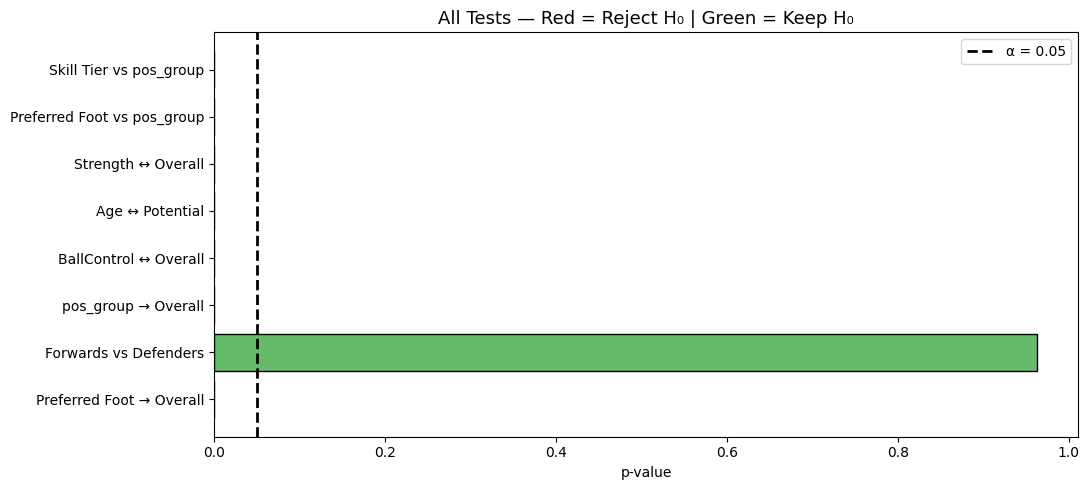

In [ ]:
# 7b — Final p-value Bar Chart

test_labels = [
    'Preferred Foot → Overall',
    'Forwards vs Defenders',
    'pos_group → Overall',
    'BallControl ↔ Overall',
    'Age ↔ Potential',
    'Strength ↔ Overall',
    'Preferred Foot vs pos_group',
    'Skill Tier vs pos_group'
]

p_values = results_df['p_value'].tolist()

colors = [
    '#ef5350' if p <= 0.05 else '#66bb6a'
    for p in p_values
]

fig, ax = plt.subplots(figsize=(11, 5))

ax.barh(
    test_labels,
    p_values,
    color=colors,
    edgecolor='black'
)

ax.axvline(
    0.05,
    color='black',
    linestyle='--',
    linewidth=2,
    label='α = 0.05'
)

ax.set_xlabel('p-value')

ax.set_title(
    'All Tests — Red = Reject H₀ | Green = Keep H₀',
    fontsize=13
)

ax.legend()

plt.tight_layout()
plt.show()

---
### 7c. Scouting Team Brief ✍️ — Written Section (5 marks)

Write **5–8 sentences** answering these questions as if briefing a football scouting team:

> 1. **Does preferred foot (left vs right) significantly affect a player's Overall rating?**
>    What did the test show, and what does that mean for scouting?
>
> 2. **Which position group has the highest average Overall?** Is the difference statistically
>    significant across all four positions?
>
> 3. **What is the single strongest predictor of a player's Overall rating?**
>    Refer to your correlation values.
>
> 4. **What happens to a player's Potential as they age?** Is this relationship
>    statistically significant? What does this mean for investing in young players?
>
> 5. **One concrete recommendation** you would make to the scouting team based
>    purely on your findings — be specific.

*Write your brief below as comments or in a new markdown cell.*


In [ ]:
# 7c — Useful values for Scouting Brief

print("Preferred Foot means:")
print(df.groupby('Preferred Foot')['Overall'].mean())

print("\nPosition means:")
print(df.groupby('pos_group')['Overall'].mean())

print("\nStrongest correlation with Overall:")

overall_corr = (
    df[cols5a]
    .corr()['Overall']
    .drop('Overall')
    .sort_values(ascending=False)
)

print(overall_corr)

print("\nAge vs Potential:")
print("Correlation:", age_rho)
print("p-value:", age_p)

Preferred Foot means:
Preferred Foot
Left     66.803516
Right    66.087961
Name: Overall, dtype: float64

Position means:
pos_group
Defender      66.400102
Forward       66.397016
GK            64.603457
Midfielder    66.545774
Name: Overall, dtype: float64

Strongest correlation with Overall:
Potential       0.660947
Value_EUR       0.627025
ShortPassing    0.502275
BallControl     0.460034
Age             0.453354
Dribbling       0.372358
Stamina         0.365652
Strength        0.349318
Finishing       0.332674
Name: Overall, dtype: float64

Age vs Potential:
Correlation: -0.2622687851097683
p-value: 3.627701901742146e-283


---
---
# 🏆 Marking Scheme
*(For instructor use)*

| Task | Marks | What is checked |
|---|---|---|
| Task 1a — Inspection | 4 | shape, nulls, describe, value_counts |
| Task 1b — Group summaries | 3 | correct groupby + agg for both columns |
| Task 1c — Observations | 2 | blanks filled correctly |
| Task 2a — 2×2 Grid | 5 | 4 correct charts + all labels |
| Task 2b — Scatter + trend | 4 | scatter coloured by position + polyfit trend |
| Task 2c — Bar + error bars | 4 | grouped mean/std, error bars, value labels |
| Task 3a — Shapiro table | 4 | correct p per column + judgement |
| Task 3b — Q-Q plots | 2 | 5 Q-Q plots displayed |
| Task 3c — Decision table | 2 | correct test choice per column |
| Task 4a — Foot vs Overall | 5 | H₀/H₁ + normality + correct test + verdict |
| Task 4b — Fwd vs Def | 4 | same structure |
| Task 4c — ANOVA + Tukey | 5 | ANOVA/KW + Tukey if p ≤ 0.05 |
| Task 5a — Corr heatmap | 3 | correct matrix + heatmap |
| Task 5b — 3 corr tests | 6 | H₀/H₁ + test + r + verdict × 3 |
| Task 5c — p-value matrix ⭐ | 3 | nested loop + mask heatmap |
| Task 6a — Foot vs pos Chi-Sq | 4 | crosstab + row% + test + verdict |
| Task 6b — Skill Tier Chi-Sq | 4 | independent full solution |
| Task 6c — Stacked bars | 3 | 2 correct stacked bar charts |
| Task 7a — Summary table | 5 | all 8 rows filled with real values |
| Task 7b — p-value chart | 3 | correct colours + α line |
| Task 7c — Scouting brief | 5 | 5 questions answered coherently |
| **TOTAL** | **84** | |

---

### ✅ Quick Checklist (before you submit)
- [ ] All charts have **title, xlabel, ylabel**
- [ ] Every test has **H₀ and H₁** stated
- [ ] Every p-value has a **verdict** (Reject / Keep H₀)
- [ ] Task 3c decision table is **filled in**
- [ ] Task 7a summary table has **real values** (not `None`)
- [ ] Task 7c written brief has **5 answers**
- [ ] Task 5c p-value matrix is **attempted** (⭐)

---
*The beautiful game, made more beautiful with data. ⚽📊*
